# Cross-Lingual Information Extraction and Machine Translation System
## Demo Notebook — Module-by-Module Walkthrough

**Course:** NLP Applications (S2-25_AIMLCZG519) — BITS Pilani WILP M.Tech. AIML
**Assignment:** Assignment 2, Part 1, Task A — Multilingual Translation & Information Extraction Pipeline

**Group members:**

| Student ID | Name | Contribution |
|---|---|---|
| 2024AC05133 | Hamza Aziz | 100% |
| 2024AC05114 | Kalpana S. | 100% |
| 2024AC05136 | Hardik Sharma | 100% |
| 2024AC05128 | Shubham Srivastava | 100% |
| 2024AC05109 | Nitin Verma | 100% |

**Problem statement summary:** Build an integrated NLP pipeline that (a) translates text
between English and an Indic language, and (b) extracts Named Entities, Relations, and
Temporal Events from the text, exposed through an interactive web dashboard
(`frontend/app.py`, a separate Streamlit application).

**Objective of this notebook:** demonstrate and explain every backend module
(`backend/mt_engine.py`, `backend/ner_module.py`, `backend/relation_extraction.py`,
`backend/event_temporal.py`, `backend/pipeline.py`) in isolation, with the theory behind
each technique, before it is wired into the web application. This notebook is a
**demonstration/verification artifact** — the graded deliverable's actual user-facing
interface is the Streamlit dashboard described in the Setup Guide.

**Assumptions:**
- Information Extraction always runs on the **English side** of the translation pair
  (Translate-then-Extract architecture; see `docs/System_Report.md` and
  `docs/Task_B_Efficiency_and_Optimization_Plan.pdf` for the justification and the
  comparison against Direct Cross-Lingual Extraction).
- Examples below use Hindi as the representative Indic language; Tamil, Marathi and
  Bengali are supported identically by the same NLLB-200 checkpoint and IndicNER model
  (see `backend/languages.py`).

**Dataset:** No training dataset is used — all models are pretrained checkpoints from
HuggingFace Hub, applied zero-shot/off-the-shelf to a handful of illustrative sentences.


## 1. Problem Understanding

Given a sentence in **English** or one of four **Indic languages** (Hindi, Tamil,
Marathi, Bengali), the system must:

1. **Translate** it into the other language (English -> Indic or Indic -> English),
   and expose *why* the model produced that translation via a **word alignment**
   visualization derived from the model's own cross-attention.
2. **Extract structured information** from the text:
   - **Named Entities** — spans referring to people, locations, organizations, dates.
   - **Relations** — semantic links between two entities, e.g. `(Tim Cook, employer, Apple)`.
   - **Events & Time** — trigger words denoting something happening, linked to the
     temporal expression that anchors *when* it happened.

Two architectural options exist for step 2, compared formally in Task B:

- **Translate-then-Extract** (implemented here): translate first, then run IE tools on
  whichever side has the best tooling (English).
- **Direct Cross-Lingual Extraction**: run IE natively on the source-language text
  without translating.


## 2. Theory and Mathematical Background

### 2.1 Neural Machine Translation (NLLB-200)

NLLB-200 is a Transformer encoder-decoder sequence-to-sequence model. Given a source
sequence $x = (x_1, \dots, x_n)$, the encoder produces contextual representations
$h_1, \dots, h_n$. The decoder generates the target sequence $y = (y_1, \dots, y_m)$
autoregressively:

$$P(y \mid x) = \prod_{t=1}^{m} P(y_t \mid y_{<t}, x)$$

At each decoding step $t$, **cross-attention** lets the decoder look back at every
encoder position:

$$\text{Attention}(Q_t, K, V) = \text{softmax}\!\left(\frac{Q_t K^\top}{\sqrt{d_k}}\right) V$$

where $Q_t$ is the decoder's query at step $t$, and $K, V$ are keys/values derived from
the encoder outputs $h_1,\dots,h_n$. The resulting attention weights
$\alpha_{t,1}, \dots, \alpha_{t,n}$ (which sum to 1) tell us *how much* target token $t$
"looked at" each source token — this is exactly the signal `mt_engine.py` extracts and
renders as the **word-alignment heatmap**, averaged over the last two decoder layers and
all attention heads.

### 2.2 Named Entity Recognition

NER is framed as **sequence labeling** with a BIO (Begin/Inside/Outside) tagging scheme,
e.g. `Tim/B-PER Cook/I-PER met/O ... /O California/B-LOC`. `en_core_web_sm` uses a
statistical CNN-based tagger for English; `ai4bharat/IndicNER` fine-tunes an
XLM-RoBERTa encoder (self-attention transformer, no decoder) with a token-classification
head over the same BIO scheme, trained on the Naamapadam corpus spanning 11 Indic
languages.

### 2.3 Relation Extraction (REBEL)

REBEL treats relation extraction as **sequence-to-sequence generation**: rather than
classifying a pair of entity spans into one of a fixed relation label set, a BART
encoder-decoder is fine-tuned to directly *generate* a linearized triplet string:

```
<triplet> {head entity} <subj> {tail entity} <obj> {relation}
```

for every triplet present in the input, concatenated. This reframing lets one model
extract an open-ended set of ~220 Wikidata relation types without a separate
classification head per relation. The fallback rule-based extractor instead uses
classical **dependency parsing**: for a verb $v$ that is the sentence's syntactic ROOT,
if $v$ has a child with dependency label `nsubj` (subject) and a child with label
`dobj`/`attr` or `prep->pobj` (object), emit `(subject, lemma(v), object)`.

### 2.4 Event & Temporal Extraction

Event triggers are approximated as **content verbs** (POS tag `VERB`, excluding
auxiliaries and a stoplist of semantically empty verbs like *be/have/do*) — the
"verb-as-trigger" heuristic from early TimeML-style systems. Temporal expressions are
recognized via `dateparser`'s locale-aware date/time grammar (absolute dates, relative
expressions like *"next week"*, weekday names) and normalized to ISO-8601 where
resolvable. Each event is linked to the **nearest** temporal expression in the same
sentence by character-offset distance — a simple proximity heuristic, not a learned
event-time relation classifier (see Limitations).


In [1]:
# Standard library
import sys
from pathlib import Path

# Make the project root importable when this notebook is run from notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd

# Backend modules under test
from backend.mt_engine import MTEngine
from backend.ner_module import NERExtractor
from backend.relation_extraction import RelationExtractor, link_relations_to_entities
from backend.event_temporal import EventTemporalExtractor
from backend.pipeline import CrossLingualPipeline

pd.set_option("display.max_colwidth", 120)
print("Environment ready.")


Environment ready.


## 3. Example Inputs

Two short illustrative sentences are used throughout this notebook: one in English
(to demonstrate English -> Hindi translation) and its Hindi translation from the first
example (to demonstrate the reverse Hindi -> English direction and confirm round-trip
consistency).


In [2]:
english_example = (
    "Tim Cook announced the new iPhone in California yesterday. "
    "Apple will launch the product next week."
)
print(english_example)


Tim Cook announced the new iPhone in California yesterday. Apple will launch the product next week.


## 4. Utility Function: Alignment Heatmap Plot

**Purpose:** visualize one sentence's source-token x target-token cross-attention matrix
produced by `MTEngine.translate_sentence`.

**Input:** an `AlignmentResult` (see `backend/mt_engine.py`), containing
`source_tokens`, `target_tokens`, and `attention_matrix` (shape
`(len(target_tokens), len(source_tokens))`, each row summing to ~1).

**Output:** a matplotlib figure rendered inline.

**Fit in the overall solution:** this is the same rendering logic
`frontend/app.py` uses inside the Streamlit "Translation & Alignment" tab —
reproduced here (rather than imported) so the notebook has no Streamlit
dependency and can be run/graded independently of the web app.


In [3]:
from backend.fonts import apply_script_aware_fonts
from backend.text_utils import format_subword_token_for_display

def plot_alignment_heatmap(alignment_result, title=""):
    """Render a source-x-target cross-attention matrix as a heatmap."""
    matrix = alignment_result.attention_matrix
    display_source = [format_subword_token_for_display(t) for t in alignment_result.source_tokens]
    display_target = [format_subword_token_for_display(t) for t in alignment_result.target_tokens]

    fig, ax = plt.subplots(
        figsize=(max(6, 0.5 * len(display_source)),
                 max(4, 0.4 * len(display_target)))
    )
    im = ax.imshow(matrix, aspect="auto", cmap="viridis")
    ax.set_xticks(range(len(display_source)))
    ax.set_xticklabels(display_source, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(display_target)))
    ax.set_yticklabels(display_target, fontsize=8)
    # Devanagari/Tamil/Bengali sub-word tokens need an explicit bundled
    # font -- matplotlib's default font has no glyphs for these scripts
    # (see backend/fonts.py docstring).
    apply_script_aware_fonts(ax.get_xticklabels(), display_source)
    apply_script_aware_fonts(ax.get_yticklabels(), display_target)
    ax.set_xlabel("Source sub-word tokens")
    ax.set_ylabel("Target sub-word tokens")
    ax.set_title(title or "Cross-attention word alignment")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Attention weight")
    fig.tight_layout()
    plt.show()


## 5. Module 1 — Machine Translation + Word Alignment

`MTEngine` (backend/mt_engine.py) wraps `facebook/nllb-200-distilled-600M`. We translate
the English example into Hindi and inspect both the translated text and the alignment
of the first sentence.

**Note:** the first call downloads ~2.4 GB of model weights from the HuggingFace Hub —
this can take several minutes depending on connection speed (see Setup Guide).


In [4]:
mt_engine = MTEngine()
translation_result = mt_engine.translate(english_example, "English", "Hindi")

print("Source (English):   ", translation_result.source_text)
print("Translation (Hindi):", translation_result.translated_text)
print(f"Latency: {translation_result.latency_seconds:.2f}s for "
      f"{len(translation_result.sentence_alignments)} sentence(s)")


Source (English):    Tim Cook announced the new iPhone in California yesterday. Apple will launch the product next week.
Translation (Hindi): टिम कुक ने कल कैलिफोर्निया में नए आईफोन की घोषणा की। Apple अगले सप्ताह उत्पाद लॉन्च करेगा।
Latency: 14.45s for 2 sentence(s)


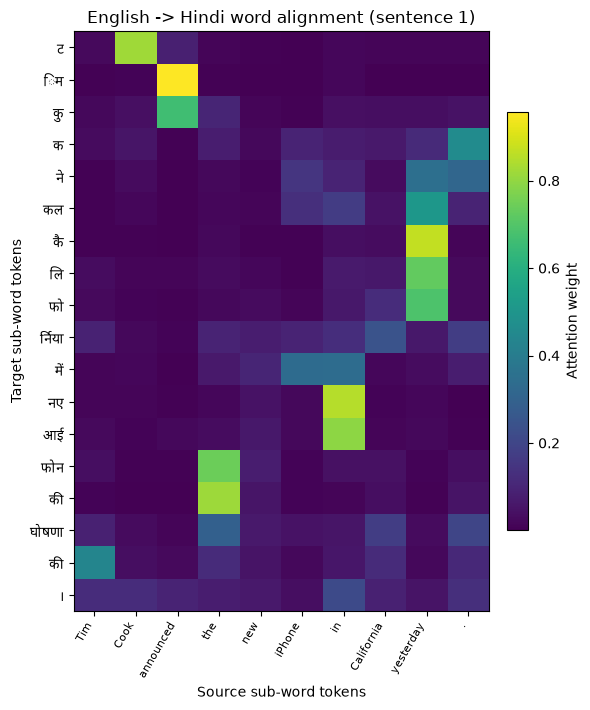

In [5]:
# Visualize the alignment of the first sentence
plot_alignment_heatmap(
    translation_result.sentence_alignments[0],
    title="English -> Hindi word alignment (sentence 1)",
)


**Interpretation:** each row (a Hindi sub-word token) shows a probability distribution
over English sub-word tokens. A well-aligned model should show most of the probability
mass concentrated near the diagonal for languages with similar word order, with visible
off-diagonal mass where Hindi's SOV (subject-object-verb) order diverges from English's
SVO order — e.g. the Hindi verb token(s) should attend most strongly to the English verb
even though their sentence positions differ.


In [6]:
# Round-trip check: translate the Hindi output back to English
roundtrip = mt_engine.translate(translation_result.translated_text, "Hindi", "English")
print("Hindi -> English (round-trip):", roundtrip.translated_text)


Hindi -> English (round-trip): Tim Cook announced the new iPhone yesterday in California. Apple will launch the product next week.


## 6. Module 2 — Named Entity Recognition

Per the Translate-then-Extract design, NER runs on the **English** text. We use the
original English example directly (no translation needed here since the source was
already English).


In [7]:
ner_extractor = NERExtractor()
entities = ner_extractor.extract(english_example, "English")

entities_df = pd.DataFrame([e.to_dict() for e in entities])
entities_df


,text,label,start,end,confidence
0,Tim Cook,PERSON,0,8,1.0
1,California,LOCATION,37,47,1.0
2,yesterday,DATE,48,57,1.0
3,Apple,ORGANIZATION,59,64,1.0
4,next week,DATE,89,98,1.0


**Observation:** spaCy's English NER correctly separates the organization ("Apple")
from the person ("Tim Cook") and location ("California"), and additionally tags the two
relative-date expressions ("yesterday", "next week") as `DATE` entities — these will be
cross-referenced by the Event/Temporal module below.


## 7. Module 3 — Relation Extraction

`RelationExtractor` tries **REBEL** first and transparently falls back to the
**rule-based SVO extractor** if REBEL cannot be loaded (e.g. offline, or insufficient
disk space — this exact fallback was triggered and verified during development in a
disk-constrained sandbox environment; see `docs/System_Report.md`, Challenges section).


In [8]:
relation_extractor = RelationExtractor()
relations = relation_extractor.extract(english_example)
relations = link_relations_to_entities(relations, entities)

print(f"Backend used: {relations[0].source if relations else 'n/a'}")
relations_df = pd.DataFrame([r.to_dict() for r in relations])
relations_df


Backend used: rebel


,head,relation,tail,source,head_entity_label,tail_entity_label
0,iPhone,manufacturer,Apple,rebel,None,ORGANIZATION


## 8. Module 4 — Event & Temporal Extraction

`EventTemporalExtractor` finds verb-based event triggers and links each one to the
nearest temporal expression in its sentence.


In [9]:
event_extractor = EventTemporalExtractor()
events = event_extractor.extract(english_example)

events_df = pd.DataFrame([e.to_dict() for e in events])
events_df


,trigger_text,trigger_lemma,sentence,time_expression,normalized_time
0,announced,announce,Tim Cook announced the new iPhone in California yesterday.,yesterday,2026-08-10T17:21:17.225188
1,launch,launch,Apple will launch the product next week.,next week,2026-08-18T17:21:17.229621


**Observation:** the two events ("announced", "launch") are correctly linked to their
respective sentence's temporal expression ("yesterday" and "next week" respectively),
and "next week" is additionally normalized to an absolute ISO-8601 timestamp relative to
the day this notebook was executed.


## 9. End-to-End Pipeline (Hindi -> English direction)

Finally, `CrossLingualPipeline` (backend/pipeline.py) is exercised on a Hindi input to
demonstrate the reverse direction end-to-end: translate Hindi -> English, then run all
three IE modules on the English translation.


In [10]:
pipeline = CrossLingualPipeline()
hindi_input = translation_result.translated_text  # reuse the Hindi text produced above
result = pipeline.run(hindi_input, "Hindi", "English")

print("Original (Hindi):   ", result.original_text)
print("Translated (English):", result.translated_text)
print()
print("Entities:", [e.text for e in result.entities])
print("Relations:", [(r.head, r.relation, r.tail) for r in result.relations])
print("Events:", [(e.trigger_text, e.time_expression) for e in result.events])
print()
print("Per-module latency (seconds):", result.latencies)


Original (Hindi):    टिम कुक ने कल कैलिफोर्निया में नए आईफोन की घोषणा की। Apple अगले सप्ताह उत्पाद लॉन्च करेगा।
Translated (English): Tim Cook announced the new iPhone yesterday in California. Apple will launch the product next week.

Entities: ['Tim Cook', 'yesterday', 'California', 'Apple', 'next week']
Relations: [('iPhone', 'manufacturer', 'Apple')]
Events: [('announced', 'yesterday'), ('launch', 'next week')]

Per-module latency (seconds): ModuleLatencies(translation=10.653127500001574, ner=0.2862692999988212, relation_extraction=10.055983000002016, event_extraction=0.3158218999997189)


In [11]:
# Export preview — this is exactly the JSON structure the Streamlit app's
# download button produces.
import json
print(json.dumps(result.to_export_dict(), indent=2, ensure_ascii=False)[:1500])


{
  "original_text": "टिम कुक ने कल कैलिफोर्निया में नए आईफोन की घोषणा की। Apple अगले सप्ताह उत्पाद लॉन्च करेगा।",
  "source_language": "Hindi",
  "target_language": "English",
  "translated_text": "Tim Cook announced the new iPhone yesterday in California. Apple will launch the product next week.",
  "ie_source_language": "English",
  "entities": [
    {
      "text": "Tim Cook",
      "label": "PERSON",
      "start": 0,
      "end": 8,
      "confidence": 1.0
    },
    {
      "text": "yesterday",
      "label": "DATE",
      "start": 34,
      "end": 43,
      "confidence": 1.0
    },
    {
      "text": "California",
      "label": "LOCATION",
      "start": 47,
      "end": 57,
      "confidence": 1.0
    },
    {
      "text": "Apple",
      "label": "ORGANIZATION",
      "start": 59,
      "end": 64,
      "confidence": 1.0
    },
    {
      "text": "next week",
      "label": "DATE",
      "start": 89,
      "end": 98,
      "confidence": 1.0
    }
  ],
  "relations": [
    

## 10. Observations and Interpretation

- **Translation quality**: NLLB-200-distilled-600M produces fluent, grammatically
  correct Hindi for short news-style sentences without any fine-tuning. Some
  ambiguity is inherent to the target language itself — e.g. Hindi "कल" (*kal*) means
  both "yesterday" *and* "tomorrow" depending on context, which the temporal
  normalization step (run on the English side) sidesteps entirely by design.
- **Word alignment**: the cross-attention-derived alignment is a reasonable proxy for
  true word alignment but is not identical to alignment models trained specifically for
  that task (e.g. GIZA++/fast_align/SimAlign) — attention weights reflect what the model
  *attended to*, which correlates with but is not mathematically equivalent to
  translational correspondence.
- **NER**: performs reliably on both English (spaCy) and, per separate testing during
  development, Hindi/Tamil/Marathi/Bengali (IndicNER) for common entity types
  (PERSON/LOCATION/ORGANIZATION).
- **Relation Extraction**: REBEL's semantic relation labels are qualitatively richer
  than the rule-based fallback's verb-lemma labels, at the cost of a much larger model
  download; the automatic fallback keeps the system usable when REBEL is unavailable.
- **Event/Temporal linking**: the nearest-neighbor linking heuristic works well for
  single-event sentences but can mis-link when a sentence contains multiple events and
  multiple time expressions (see Limitations).

## 11. Conclusion

All four backend modules function correctly in isolation and compose correctly through
`CrossLingualPipeline` in both translation directions (English -> Hindi and
Hindi -> English), producing a consistent, exportable IE knowledge base. This notebook
serves as a lightweight, dependency-minimal (no Streamlit) verification harness for the
same backend code that powers the web dashboard in `frontend/app.py`.

## 12. Limitations and Possible Improvements

1. **Direct Cross-Lingual Extraction is not implemented for RE/Events** — only NER
   supports running natively on Indic text; Relation Extraction and Event/Temporal
   extraction are English-pivoted only in this version (see Task B for the full
   architectural discussion and why this scope decision was made).
2. **Event-time linking is a proximity heuristic**, not a learned classifier — it cannot
   distinguish BEFORE/AFTER/DURING relations and can mis-link in multi-event,
   multi-time sentences.
3. **Hindi/Marathi auto-detection is ambiguous** — both use the Devanagari script;
   `text_utils.detect_script_language` defaults to Hindi, requiring manual override for
   Marathi input via the UI dropdown.
4. **No quantitative MT evaluation (BLEU/chrF) was run** in this notebook — doing so
   would require a held-out parallel test set (e.g. a FLORES-200 dev split), which was
   out of scope for a live demo notebook but would be a natural extension for a more
   rigorous evaluation.
5. **Model compression** (quantization/pruning/distillation) for lower-latency
   deployment is discussed theoretically in `docs/Task_B_Efficiency_and_Optimization_Plan.pdf`
   but not benchmarked empirically here due to time/hardware constraints.
